# 2. Dynamic pricing engine: how much revenue is on the table?

Indian Railways sells 3A seats on train 12138 at a fixed fare. Airlines instead change fares with demand, seats left and time to departure. This notebook builds a booking simulator calibrated to the train's real bookings and asks: **how much more revenue would dynamic pricing earn, and which pricing method should be used?**

### How the simulator works

| Ingredient | Source |
|---|---|
| Booking curve: share of passengers booking each day before departure | Real 3A bookings, journeys from Mar 2025 (60-day booking window) |
| How busy each departure is | Real daily 3A totals, Aug 2023 – Jul 2025 |
| Forecast the pricer sees before booking opens | Calendar blend from [`01_demand_forecasting.ipynb`](01_demand_forecasting.ipynb) |
| Bookings each day | Random (Poisson) whole passengers, capped at the seats left |
| Price response | **Assumed** constant elasticity, tested over a range (fares never changed in the data) |
| The coach | 90 seats, ₹1,100 base fare, 60-day booking window, fares from –15% to +30% |

**Evaluation.** Policies are trained or tuned on Aug 2023 – Jul 2024 departures and tested on all 365 departures from Aug 2024 – Jul 2025, which they never saw. Each departure is simulated 20 times, and every policy faces exactly the same random customers, so differences come from the policy, not luck. Revenue gains are reported with paired 95% confidence intervals.

The simulator is in [`src/pricing_sim.py`](../src/pricing_sim.py). Its maths is checked by [`tests/test_pricing_sim.py`](../tests/test_pricing_sim.py); for example, the optimizer's predicted revenue matches simulation to within 1%.

**Policies compared**

- **Fixed fare (today):** ₹1,100 every day.
- **Pacing rule:** a simple rule. Start the fare according to the forecast, raise it when bookings run ahead of plan, and lower it when they run behind.
- **Q-learning agent:** reinforcement learning. It watches days to departure, seats left, booking pace and the forecast, and learns from 60,000 simulated departures.
- **Forecast + optimizer:** classic airline revenue management. Forecast the departure's demand, then choose each day's fare by dynamic programming.
- **…re-forecasting daily:** the same, but the demand estimate is updated every day from bookings so far.
- **Perfect-information ceiling:** the optimizer, told the true demand. This is not achievable; it shows the most any policy could earn.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
from data_loader import load_bookings, daily_totals
from pricing_sim import (Market, FixedFare, PacingRule, QLearningAgent, ForecastOptimizer, BASE_FARE, CAPACITY,
                         HORIZON, booking_curve_from_bookings, demand_levels, forecast_levels, evaluate, summarize,
                         simulate)

pd.set_option("display.precision", 1)
COLUMNS = ["revenue", "load_factor_%", "avg_fare", "fare_changes", "uplift_vs_fixed_%", "uplift_ci_%",
           "passengers_vs_fixed_%"]

## 1. Calibrate to real bookings

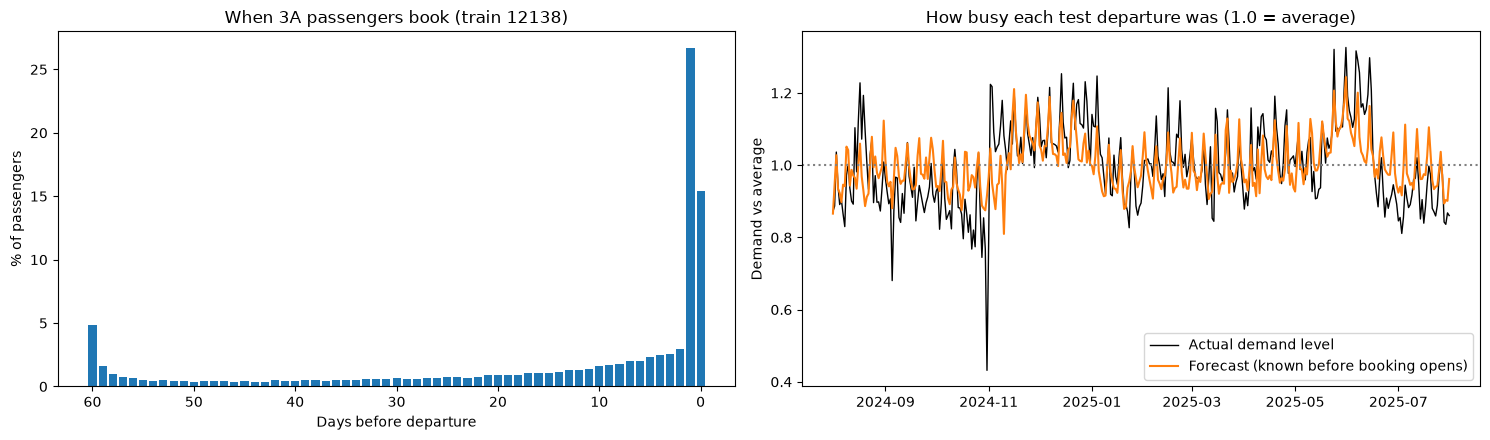

45% of passengers book within 2 days of departure, 56% within a week.
Test departures: 365; busiest 1.33x average, quietest 0.43x.
Forecast error on test departures: 6.9% on average.


In [2]:
bookings = load_bookings(cls="3A")
# Since Nov 2024 tickets open 60 days ahead; use journeys from Mar 2025 so the whole window follows the new rule
booking_curve = booking_curve_from_bookings(bookings[pd.to_datetime(bookings.journey_date) >= "2025-03-01"])

daily = daily_totals(bookings)
train = daily[daily.journey_date < "2024-08-01"]
test = daily[daily.journey_date >= "2024-08-01"]
train_levels, train_forecasts = demand_levels(train, train), forecast_levels(train, train)
test_levels, test_forecasts = demand_levels(test, train), forecast_levels(test, train)
forecast_error = np.abs(test_levels.values / test_forecasts.values - 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(range(HORIZON + 1), 100 * booking_curve, color="tab:blue")
axes[0].set(title="When 3A passengers book (train 12138)", xlabel="Days before departure",
            ylabel="% of passengers")
axes[0].invert_xaxis()
axes[1].plot(test_levels.index, test_levels, color="black", lw=1, label="Actual demand level")
axes[1].plot(test_forecasts.index, test_forecasts, color="tab:orange", lw=1.5,
             label="Forecast (known before booking opens)")
axes[1].axhline(1, color="gray", ls=":")
axes[1].set(title="How busy each test departure was (1.0 = average)", ylabel="Demand vs average")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"{100 * booking_curve[:3].sum():.0f}% of passengers book within 2 days of departure, "
      f"{100 * booking_curve[:8].sum():.0f}% within a week.")
print(f"Test departures: {len(test_levels)}; busiest {test_levels.max():.2f}x average, quietest {test_levels.min():.2f}x.")
print(f"Forecast error on test departures: {100 * forecast_error.mean():.1f}% on average.")

## 2. Head-to-head in four scenarios

Two things the booking data cannot tell us decide how much dynamic pricing is worth:

- **Price sensitivity (elasticity).** How many bookings are lost when the fare rises 10%? The fares in the data never changed, so this has to come from a fare experiment. We test 1.2 (a 10% rise loses about 11% of bookings) and 0.8 (it loses about 7%).
- **Demand vs capacity.** We test 75 bookings per 90-seat coach at the base fare (spare seats) and, because popular Indian Railways trains are often waitlisted, 95 (oversubscribed on average).

Each policy is tested on all 365 departures from the second year, with 20 random booking windows each.

In [3]:
SCENARIOS = {"Price-sensitive, spare seats": (1.2, 75), "Price-sensitive, oversubscribed": (1.2, 95),
             "Less price-sensitive, spare seats": (0.8, 75), "Less price-sensitive, oversubscribed": (0.8, 95)}
summaries, markets = {}, {}
for label, (elasticity, demand) in SCENARIOS.items():
    market = Market(booking_curve, elasticity=elasticity, demand_at_base=demand)
    agent = QLearningAgent(seed=0).train(market, train_levels, train_forecasts, episodes=60_000)
    policies = [FixedFare(), PacingRule(), agent, ForecastOptimizer(),
                ForecastOptimizer(reforecast=True, forecast_cv=0.10)]
    results = evaluate(policies, market, test_levels, test_forecasts, runs_per_departure=20)
    summaries[label], markets[label] = summarize(results), market
    print(f"\n=== {label} (elasticity {elasticity}, {demand} bookings per 90 seats at base fare) ===")
    display(summaries[label][COLUMNS])


=== Price-sensitive, spare seats (elasticity 1.2, 75 bookings per 90 seats at base fare) ===


,revenue,load_factor_%,avg_fare,fare_changes,uplift_vs_fixed_%,uplift_ci_%,passengers_vs_fixed_%
policy,,,,,,,
Fixed fare (today),81513.3,82.3,1100.0,0.0,0.0,0.0,0.0
Q-learning agent,81769.0,84.7,1072.6,11.5,0.3,0.1,2.9
Pacing rule,82050.8,83.2,1096.2,7.5,0.7,0.1,1.0
Forecast + optimizer,83170.6,91.8,1006.2,6.3,2.0,0.1,11.5
"Forecast + optimizer, re-forecasting daily",83199.6,91.5,1010.4,8.3,2.1,0.1,11.1
Perfect-information ceiling,83265.0,91.6,1010.6,6.2,2.1,0.1,11.2



=== Price-sensitive, oversubscribed (elasticity 1.2, 95 bookings per 90 seats at base fare) ===


,revenue,load_factor_%,avg_fare,fare_changes,uplift_vs_fixed_%,uplift_ci_%,passengers_vs_fixed_%
policy,,,,,,,
Fixed fare (today),95110.2,96.1,1100.0,0.0,0.0,0.0,0.0
Pacing rule,97829.2,97.9,1110.6,8.3,2.9,0.2,1.9
Q-learning agent,99119.4,94.5,1166.0,12.3,4.2,0.1,-1.7
Forecast + optimizer,101337.2,94.3,1194.3,10.5,6.5,0.2,-1.9
"Forecast + optimizer, re-forecasting daily",101370.0,94.6,1190.9,13.5,6.6,0.2,-1.6
Perfect-information ceiling,101568.3,94.7,1191.9,9.8,6.8,0.2,-1.4



=== Less price-sensitive, spare seats (elasticity 0.8, 75 bookings per 90 seats at base fare) ===


,revenue,load_factor_%,avg_fare,fare_changes,uplift_vs_fixed_%,uplift_ci_%,passengers_vs_fixed_%
policy,,,,,,,
Fixed fare (today),81513.3,82.3,1100.0,0.0,0.0,0.0,0.0
Pacing rule,82146.6,83.0,1100.3,7.5,0.8,0.1,0.8
Q-learning agent,85081.2,72.8,1297.9,10.7,4.4,0.1,-11.5
Forecast + optimizer,86741.1,67.4,1430.0,0.0,6.4,0.1,-18.1
"Forecast + optimizer, re-forecasting daily",86741.1,67.4,1430.0,0.0,6.4,0.1,-18.1
Perfect-information ceiling,86741.1,67.4,1430.0,0.0,6.4,0.1,-18.1



=== Less price-sensitive, oversubscribed (elasticity 0.8, 95 bookings per 90 seats at base fare) ===


,revenue,load_factor_%,avg_fare,fare_changes,uplift_vs_fixed_%,uplift_ci_%,passengers_vs_fixed_%
policy,,,,,,,
Fixed fare (today),95110.2,96.1,1100.0,0.0,0.0,0.0,0.0
Pacing rule,97982.8,97.7,1114.1,8.3,3.0,0.2,1.7
Q-learning agent,105158.9,89.7,1302.2,10.1,10.6,0.2,-6.6
Forecast + optimizer,108401.2,84.2,1430.0,0.0,14.0,0.2,-12.3
"Forecast + optimizer, re-forecasting daily",108401.2,84.2,1430.0,0.0,14.0,0.2,-12.3
Perfect-information ceiling,108401.2,84.2,1430.0,0.0,14.0,0.2,-12.3


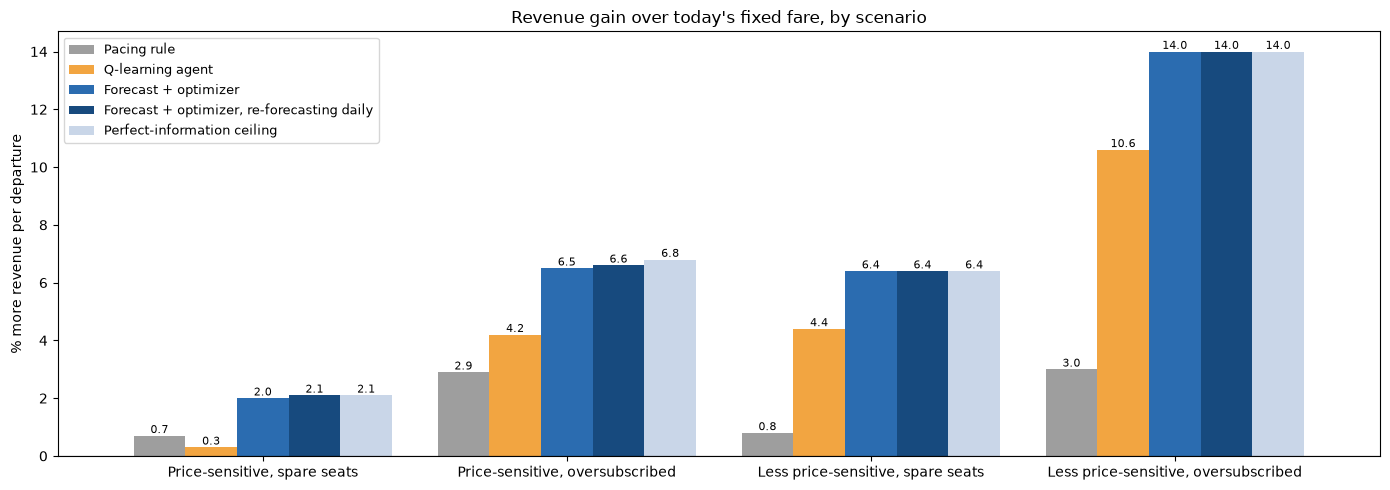

Share of the achievable gain captured (%):


,"Price-sensitive, spare seats","Price-sensitive, oversubscribed","Less price-sensitive, spare seats","Less price-sensitive, oversubscribed"
policy,,,,
Pacing rule,33.0,43.0,12.0,21.0
Q-learning agent,14.0,62.0,69.0,76.0
Forecast + optimizer,95.0,96.0,100.0,100.0
"Forecast + optimizer, re-forecasting daily",100.0,97.0,100.0,100.0


In [4]:
order = ["Pacing rule", "Q-learning agent", "Forecast + optimizer",
         "Forecast + optimizer, re-forecasting daily", "Perfect-information ceiling"]
uplift = pd.DataFrame({k: s["uplift_vs_fixed_%"] for k, s in summaries.items()}).loc[order]
ax = uplift.T.plot.bar(figsize=(14, 5), width=0.85, rot=0,
                       color=["#9e9e9e", "#f2a541", "#2b6cb0", "#174a7e", "#c9d6e8"])
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Revenue gain over today's fixed fare, by scenario", ylabel="% more revenue per departure")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=8)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

captured = (uplift.loc[["Pacing rule", "Q-learning agent", "Forecast + optimizer",
                        "Forecast + optimizer, re-forecasting daily"]]
            / uplift.loc["Perfect-information ceiling"] * 100).round(0)
print("Share of the achievable gain captured (%):")
display(captured)

### Why Q-learning falls short

Q-learning captures only **14–76%** of the achievable gain (+0.3% to +10.6% over fixed fare), while the forecast + optimizer captures **95–100%**. Five reasons:

1. **It learns by trial and error what the optimizer can calculate.** The dynamic program uses the demand model directly and finds the exact best fare for every situation. Q-learning is *model-free*: it must estimate the value of each fare in each situation from simulated outcomes. With the same information, the best it can do is match the dynamic program, and with finite training it falls short.
2. **Its view of the situation is coarse.** The Q-table has 441 states: 7 buckets of days to departure × 7 buckets of seats left × 3 booking-pace levels × 3 forecast levels. It cannot tell 16 seats left from 29, or day 8 from day 13, yet near departure exactly those differences decide the right fare. The dynamic program uses every (day, seats-left) combination exactly.
3. **Rewards are noisy and delayed.** Bookings are random, and about 45% of passengers book in the last two days, so the effect of an early fare shows up weeks later, mixed with luck. Untangling that needs a great many samples. Even after 60,000 simulated departures, rarely visited states, such as a busy departure with few seats left early on, are poorly learned, and those are where pricing matters most.
4. **Demand is only partly visible.** The agent sees a three-level forecast bucket and booking pace, while true demand varies continuously from departure to departure.
5. **Learning is expensive in the real world.** Here it learns in a simulator. Learning on live departures would mean charging deliberately random fares to real passengers, and the final policy is a lookup table that is hard to explain to a revenue manager.

It does best (76%) when passengers are less price-sensitive and the train is oversubscribed, because the right answer is simple ("charge high"). It does worst (14%) when passengers are price-sensitive and there are spare seats: the gain there is small and subtle, and random noise swamps it.

**When would reinforcement learning make sense?** When demand can't be modelled reliably: competitors reacting to your fares, passengers choosing between many trains and classes, or travellers waiting for lower prices. It also helps when the state space is too large for dynamic programming but there is abundant data or a realistic simulator. Here demand *can* be modelled, so optimizing the model directly is both better and explainable.

## 3. Where does dynamic pricing pay?

The four scenarios above are points on a map. Here the forecast + optimizer is run across a grid of price sensitivity and demand, on every third test departure.

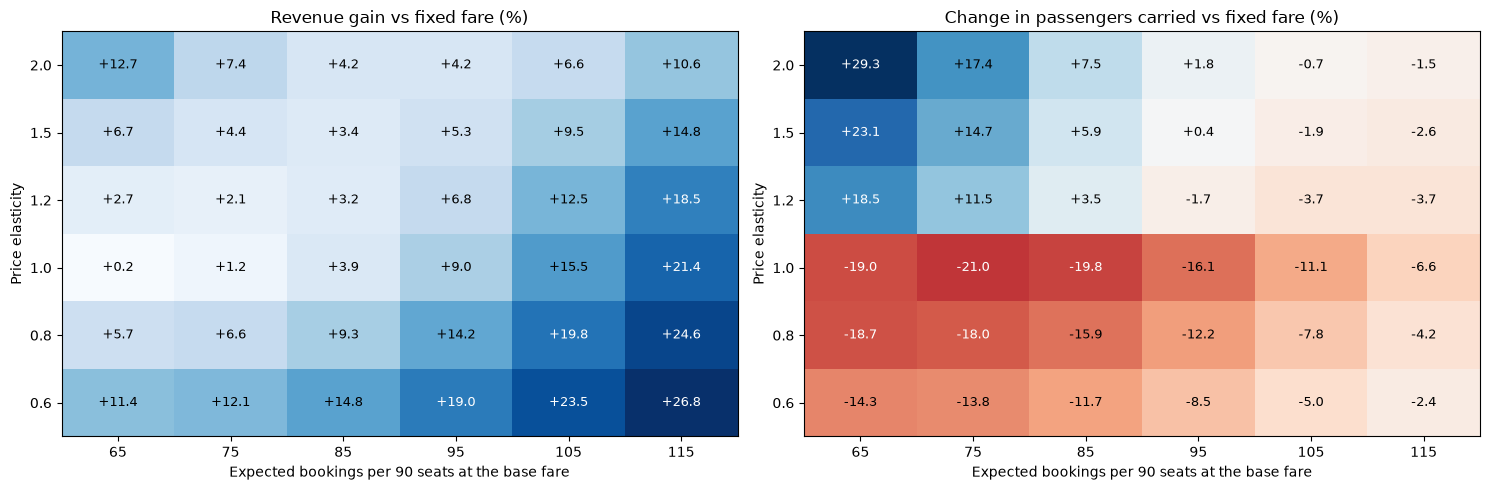

In [5]:
elasticities = [0.6, 0.8, 1.0, 1.2, 1.5, 2.0]
demands = [65, 75, 85, 95, 105, 115]
sample_levels, sample_forecasts = test_levels.iloc[::3], test_forecasts.iloc[::3]
grid_uplift = pd.DataFrame(index=elasticities, columns=demands, dtype=float)
grid_pax = grid_uplift.copy()
for e in elasticities:
    for d in demands:
        market = Market(booking_curve, elasticity=e, demand_at_base=d)
        s = summarize(evaluate([FixedFare(), ForecastOptimizer()], market, sample_levels, sample_forecasts,
                               runs_per_departure=10, with_ceiling=False))
        grid_uplift.loc[e, d] = s.loc["Forecast + optimizer", "uplift_vs_fixed_%"]
        grid_pax.loc[e, d] = s.loc["Forecast + optimizer", "passengers_vs_fixed_%"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, grid, title, cmap in [(axes[0], grid_uplift, "Revenue gain vs fixed fare (%)", "Blues"),
                              (axes[1], grid_pax, "Change in passengers carried vs fixed fare (%)", "RdBu")]:
    lim = np.abs(grid.values).max()
    im = ax.imshow(grid.values.astype(float), cmap=cmap, aspect="auto", origin="lower",
                   vmin=(-lim if cmap == "RdBu" else 0), vmax=lim)
    ax.set_xticks(range(len(demands)), [f"{d}" for d in demands])
    ax.set_yticks(range(len(elasticities)), [f"{e}" for e in elasticities])
    ax.set(xlabel="Expected bookings per 90 seats at the base fare", ylabel="Price elasticity", title=title)
    for i in range(len(elasticities)):
        for j in range(len(demands)):
            v = grid.values[i, j]
            ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(v) > 0.6 * lim else "black")
plt.tight_layout()
plt.show()

## 4. Demand surprises

The forecast in this simulator is fairly good, at about 7% error. Real departures also face surprises the calendar can't predict: a competing train cancelled, an exam, a disruption. Here each test departure's true demand is shifted by a random surprise of about ±25% that the forecast does not know about. A pricer that re-forecasts from bookings should notice and react.

In [6]:
rng = np.random.default_rng(11)
surprised_levels = test_levels * np.exp(rng.normal(0, 0.25, len(test_levels)))
market = Market(booking_curve, elasticity=1.2, demand_at_base=95)
surprise = summarize(evaluate([FixedFare(), PacingRule(), ForecastOptimizer(),
                               ForecastOptimizer(reforecast=True, forecast_cv=0.10),
                               ForecastOptimizer(reforecast=True, forecast_cv=0.25,
                                                 name="Forecast + optimizer, re-forecasting (expects surprises)")],
                              market, surprised_levels, test_forecasts, runs_per_departure=10))
display(surprise[COLUMNS])

,revenue,load_factor_%,avg_fare,fare_changes,uplift_vs_fixed_%,uplift_ci_%,passengers_vs_fixed_%
policy,,,,,,,
Fixed fare (today),91631.8,92.6,1100.0,0.0,0.0,0.0,0.0
Pacing rule,96002.6,94.7,1126.0,6.9,4.8,0.3,2.4
Forecast + optimizer,100628.2,92.3,1210.7,9.3,9.8,0.3,-0.2
"Forecast + optimizer, re-forecasting daily",100860.7,92.9,1205.8,11.6,10.1,0.4,0.4
"Forecast + optimizer, re-forecasting (expects surprises)",100967.2,93.5,1200.1,14.3,10.2,0.4,1.0
Perfect-information ceiling,101635.7,93.8,1204.1,6.4,10.9,0.4,1.3


## 5. Fairness: revenue vs passengers carried

Revenue maximization can raise fares so far that fewer people travel. A public railway might care about both. There are two ways to build that in:

- **Cap the fare,** for example at +10% or +20%.
- **Value each passenger carried.** Tell the optimizer that each passenger is worth ₹X to the railway on top of the fare paid. ₹0 is pure revenue maximization; a higher value makes it favour filling seats.

Each point below is one setting, in the two "oversubscribed" scenarios.

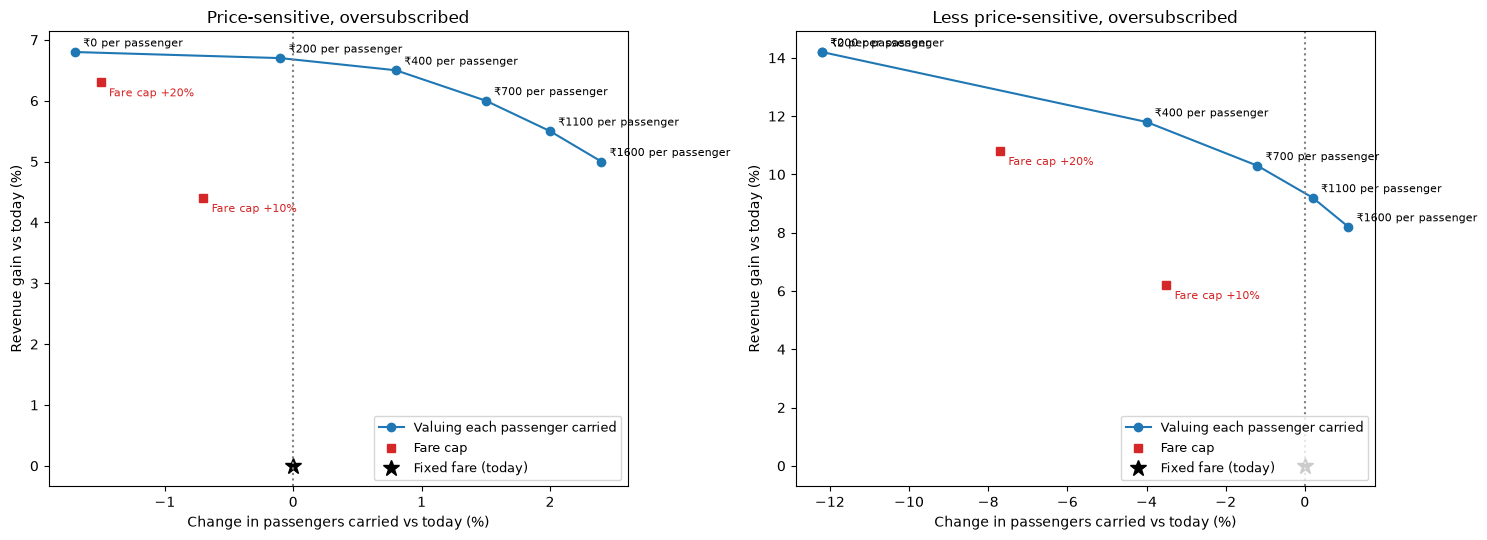


Price-sensitive, oversubscribed


,avg_fare,load_factor_%,uplift_vs_fixed_%,passengers_vs_fixed_%
policy,,,,
Fixed fare (today),1100.0,96.2,0.0,0.0
Fare cap +10%,1156.7,95.5,4.4,-0.7
₹1600 per passenger,1128.3,98.5,5.0,2.4
₹1100 per passenger,1138.2,98.1,5.5,2.0
₹700 per passenger,1149.6,97.6,6.0,1.5
Fare cap +20%,1187.0,94.7,6.3,-1.5
₹400 per passenger,1162.4,96.9,6.5,0.8
₹200 per passenger,1174.4,96.2,6.7,-0.1
₹0 per passenger,1194.9,94.6,6.8,-1.7



Less price-sensitive, oversubscribed


,avg_fare,load_factor_%,uplift_vs_fixed_%,passengers_vs_fixed_%
policy,,,,
Fixed fare (today),1100.0,96.2,0.0,0.0
Fare cap +10%,1210.0,92.9,6.2,-3.5
₹1600 per passenger,1177.9,97.2,8.2,1.1
₹1100 per passenger,1198.6,96.4,9.2,0.2
₹700 per passenger,1227.6,95.1,10.3,-1.2
Fare cap +20%,1320.0,88.8,10.8,-7.7
₹400 per passenger,1281.0,92.4,11.8,-4.0
₹0 per passenger,1430.0,84.5,14.2,-12.2
₹200 per passenger,1430.0,84.5,14.2,-12.2


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=False)
frontiers = {}
for ax, label in zip(axes, ["Price-sensitive, oversubscribed", "Less price-sensitive, oversubscribed"]):
    market = markets[label]
    values = [0, 200, 400, 700, 1100, 1600]
    caps = [1.1, 1.2]
    policies = ([FixedFare()] + [ForecastOptimizer(seat_value=v, name=f"₹{v} per passenger") for v in values]
                + [ForecastOptimizer(max_fare=c, name=f"Fare cap +{round(100 * (c - 1))}%") for c in caps])
    s = summarize(evaluate(policies, market, sample_levels, sample_forecasts, runs_per_departure=10,
                           with_ceiling=False))
    frontiers[label] = s
    v_rows = s.loc[[f"₹{v} per passenger" for v in values]]
    ax.plot(v_rows["passengers_vs_fixed_%"], v_rows["uplift_vs_fixed_%"], "o-", color="tab:blue",
            label="Valuing each passenger carried")
    for name, row in v_rows.iterrows():
        ax.annotate(name, (row["passengers_vs_fixed_%"], row["uplift_vs_fixed_%"]), textcoords="offset points",
                    xytext=(6, 4), fontsize=8)
    c_rows = s.loc[[f"Fare cap +{round(100 * (c - 1))}%" for c in caps]]
    ax.plot(c_rows["passengers_vs_fixed_%"], c_rows["uplift_vs_fixed_%"], "s", color="tab:red", label="Fare cap")
    for name, row in c_rows.iterrows():
        ax.annotate(name, (row["passengers_vs_fixed_%"], row["uplift_vs_fixed_%"]), textcoords="offset points",
                    xytext=(6, -10), fontsize=8, color="tab:red")
    ax.plot(0, 0, "k*", ms=12, label="Fixed fare (today)")
    ax.axvline(0, color="gray", ls=":")
    ax.set(title=label, xlabel="Change in passengers carried vs today (%)", ylabel="Revenue gain vs today (%)")
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()
for label, s in frontiers.items():
    print(f"\n{label}")
    display(s[["avg_fare", "load_factor_%", "uplift_vs_fixed_%", "passengers_vs_fixed_%"]])

## 6. What the optimizer does on a busy and a quiet day

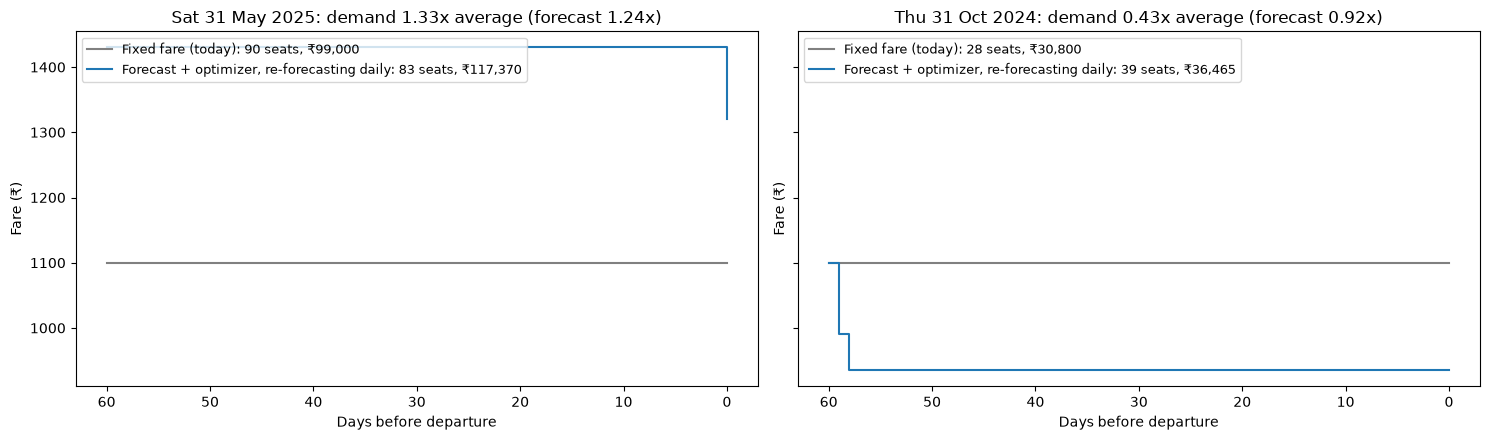

In [8]:
market = markets["Price-sensitive, oversubscribed"]
busy, quiet = test_levels.idxmax(), test_levels.idxmin()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, date in zip(axes, [busy, quiet]):
    level, fc = test_levels[date], test_forecasts[date]
    for policy, colour in [(FixedFare(), "gray"), (ForecastOptimizer(reforecast=True, forecast_cv=0.10), "tab:blue")]:
        revenue, sold, _, fares = simulate(policy, market, level, fc, n_runs=1, seed=3)
        ax.step(range(HORIZON, -1, -1), fares[0], where="post", color=colour,
                label=f"{policy.name}: {sold[0]} seats, ₹{revenue[0]:,.0f}")
    ax.invert_xaxis()
    ax.set(title=f"{date:%a %d %b %Y}: demand {level:.2f}x average (forecast {fc:.2f}x)",
           xlabel="Days before departure", ylabel="Fare (₹)")
    ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

## Takeaways

- **Forecast + optimize is the approach to build.** It captures 95–100% of the revenue that perfect knowledge of demand would allow, in every scenario. Each fare it sets can be traced to a forecast and a seats-left table that a revenue manager can inspect and override.
- **Re-forecasting from bookings is insurance.** In normal conditions it adds about 0.1 points, because the calendar forecast is already good. When demand surprises the forecast, it recovers part of the gap to the ceiling (+10.2% vs +9.8%, ceiling +10.9%). This is why airlines re-forecast continuously.
- **Simpler and fancier alternatives both fall short.** The pacing rule captures 12–43% of the achievable gain. Q-learning captures 14–76%, needs 60,000 simulated departures to train, and is harder to explain.
- **Dynamic pricing pays in two different ways** (section 3):
  - *Busy trains, passengers not very price-sensitive:* raise fares on peak days. The gain is large (+14% to +27%), but it carries fewer passengers.
  - *Spare seats, price-sensitive passengers:* discount quiet days. The gain is moderate (+2% to +13%), and it carries **more** passengers.

  The weakest case is elasticity near 1 with spare seats, where fare changes barely move revenue. Knowing which case a train is in matters more than the algorithm, and a small fare test would tell.
- **Value passengers carried rather than capping fares** (section 5). Telling the optimizer that each passenger is worth about the base fare (₹1,100) to the railway keeps ridership at or above today's level while earning +5.5% to +9.2%. Fare caps earn less *and* carry fewer people. For a public railway, this is the guard-rail to use.